In [1]:
#| include: false
%load_ext autoreload
%autoreload 2

In [ ]:
#| include: false
import os

# No GPU en este ordenata
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
import re
from pathlib import Path
from keras.callbacks import Callback
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


import ap_pec1.utils as utils


plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100


# Seed para reproducibilidad de todos los experimentos
np.random.seed(42)
tf.random.set_seed(42)
tf.keras.utils.set_random_seed(42)

I0000 00:00:1793878658.198155   17180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793878658.198674   17180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793878660.032345   17180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793878660.032777   17180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Análisis exploratorio de los datos

In [191]:
#| echo: false
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
assert x_train.shape == (60000, 28, 28)
assert x_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_test.shape == (10000,)

Para el entrenamiento y la evaluación del perceptrón multicapa (MLP), se utilizará el conjunto de datos MNIST, disponible en Keras. Este conjunto, desarrollado originalmente por Yann LeCun y Corinna Cortes, contiene imágenes de números escritos a mano del 0 al 9, representadas en escala de grises con una resolución de 28x28 píxeles.

En la @tbl-dataset-mnist se hace un breve resumen del conjunto de datos.

In [192]:
#| echo: false
#| output: asis
datasets = [
    ("Entrenamiento", "Imágenes", x_train),
    ("Prueba", "Imágenes", x_test),
    ("Entrenamiento", "Etiquetas", y_train),
    ("Prueba", "Etiquetas", y_test),
]

print("| Conjunto | Contenido | Muestras | Dimensiones | Tipo |")
print("|:---------|:----------|:---------|:------------|:-----|")
for conjunto, contenido, dataset in datasets:
    muestras = len(dataset)
    dimensiones = " x ".join(str(d) for d in dataset.shape)
    print(
        f"| {conjunto} | {contenido} | {muestras} | {dimensiones} | {dataset.dtype} |"
    )
print(": Conjunto de datos MNIST  {#tbl-dataset-mnist .striped .hover .sm}")

| Conjunto | Contenido | Muestras | Dimensiones | Tipo |
|:---------|:----------|:---------|:------------|:-----|
| Entrenamiento | Imágenes | 60000 | 60000 x 28 x 28 | uint8 |
| Prueba | Imágenes | 10000 | 10000 x 28 x 28 | uint8 |
| Entrenamiento | Etiquetas | 60000 | 60000 | uint8 |
| Prueba | Etiquetas | 10000 | 10000 | uint8 |
: Conjunto de datos MNIST  {#tbl-dataset-mnist .striped .hover .sm}


En la @fig-random-images, se muestran 20 imágenes aleatorias del conjunto de entrenamiento con el que vamos a trabajar.

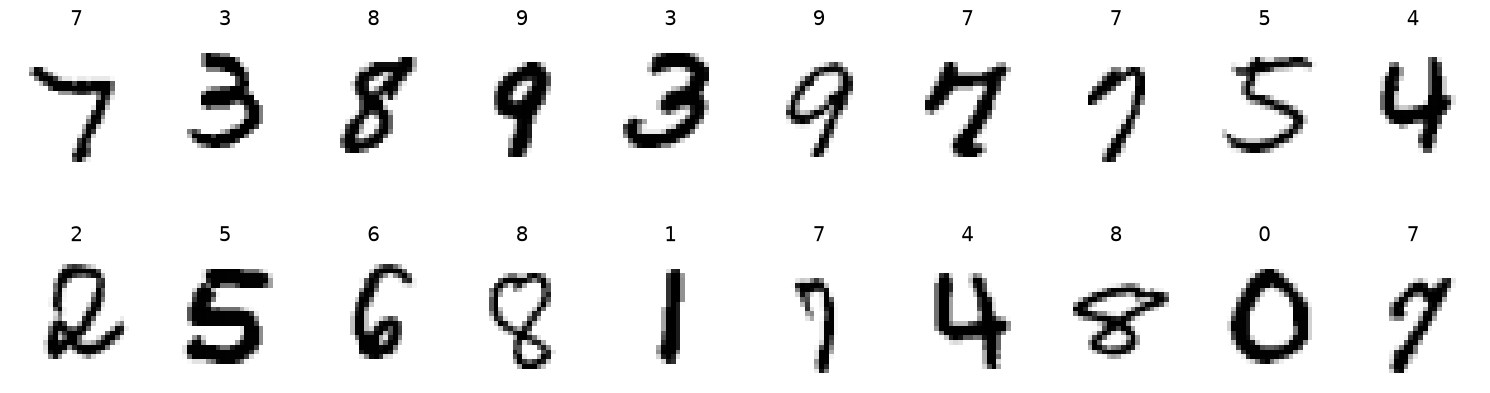

In [ ]:
#| echo: false
#| label: fig-random-images
#| fig-cap: "Muestras aleatorias de imágenes MNIST del conjunto de entrenamiento"
fig, axes = plt.subplots(2, 10, figsize=(15, 5))
axes = axes.ravel()

# Seleccionamos 20 imágenes aleatorias del conjuntos de entrenamiento
indices = np.random.permutation(x_train.shape[0])[:20]

for ax, idx in zip(axes, indices):
    img = x_train[idx]
    label = y_train[idx]
    utils.plot_image(img, ax=ax, title=str(label), cmap="binary")

plt.tight_layout()
plt.show()

Algunos números tienen trazos muy similares, @fig-images-confusion, se presupone que estos pueden ser los que generen más dificultad al modelo a la hora de clasificarlos.

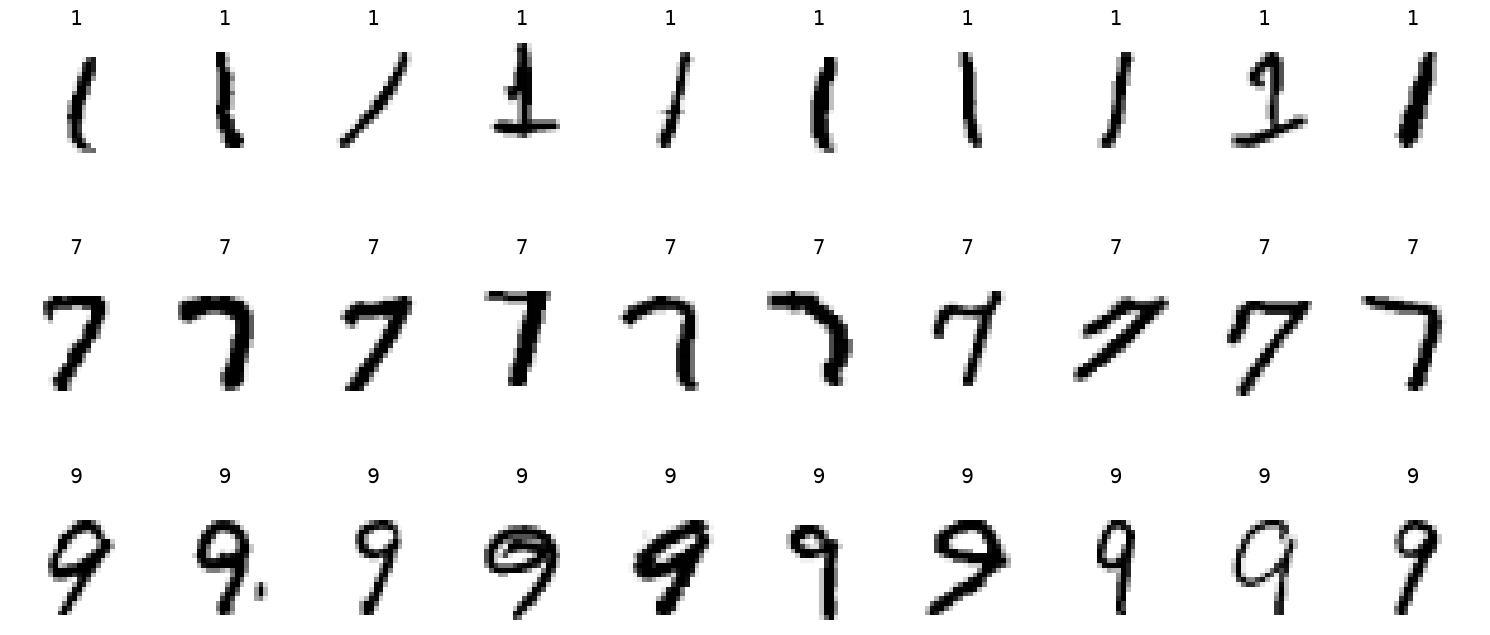

In [ ]:
#| echo: false
#| label: fig-images-confusion
#| fig-cap: "Variabilidad de los dígitos manuscritos 1, 7 y 9"
nrows = 3
ncols = 10

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 7.5))
axes = axes.ravel()

# Seleccionamos 10 imágenes aleatorias para los números 1, 7 y 9
indices_1 = np.random.permutation(np.where(y_train == 1)[0])[:10]
indices_7 = np.random.permutation(np.where(y_train == 7)[0])[:10]
indices_9 = np.random.permutation(np.where(y_train == 9)[0])[:10]

for idx in range(10):
    img_1 = x_train[indices_1[idx]]
    img_7 = x_train[indices_7[idx]]
    img_9 = x_train[indices_9[idx]]

    utils.plot_image(img_1, ax=axes[idx], title="1", cmap="binary")
    utils.plot_image(img_7, ax=axes[idx + ncols], title="7", cmap="binary")
    utils.plot_image(img_9, ax=axes[idx + 2 * ncols], title="9", cmap="binary")

plt.tight_layout()
plt.show()

Para preparar los datos para el entrenamiento, se normalizan las imágenes dividiendo por 255.0 y se realiza una división en conjunto de entrenamiento y validación.

In [7]:
# Se reserva el 20% de los datos de entrenamiento para validación
train_split = int(0.8 * x_train.shape[0])

x_train_split = x_train[:train_split].astype("float32") / 255.0
y_train_split = y_train[:train_split]
x_val_split = x_train[train_split:].astype("float32") / 255.0
y_val_split = y_train[train_split:]
x_test = x_test.astype("float32") / 255.0

# Creación de los modelos

In [8]:
#| include: false
def make_mlp(input_shape, *, hidden_layer=3, units=300, output=10):
    """
    Función plantilla para crear un MLP (Multi-Layer Perceptron).

    Parámetros:
    ===========
    - input_shape: tupla que define la forma de la entrada.
    - hidden_layer: número de capas ocultas (por defecto 3).
    - units: número de neuronas por capa oculta.
            - si es un entero, todas las capas ocultas tendrán ese número de neuronas
            - si es una lista o una tupla, cada elemento define el número de neuronas de
            la capa correspondiente.

    Retorna:
    ===========
    - modelo de Keras con la arquitectura especificada.
    """
    if isinstance(units, (list, tuple)):
        if len(units) != hidden_layer:
            raise ValueError(
                "La longitud de la lista de neuronas debe coincidir con el número de capas ocultas"
            )
    else:
        units = [units] * hidden_layer

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.InputLayer(shape=input_shape))
    model.add(tf.keras.layers.Flatten())
    for neurons in units:
        model.add(tf.keras.layers.Dense(neurons, activation="relu"))
    model.add(tf.keras.layers.Dense(output, activation="softmax"))
    return model

Para determinar el número de neuronas de las capas ocultas, se considerarán dos estrategias de diseño descritas en [@geron2022hands].

La primera, utilizada en los primeros diseños de redes neuronales, consiste en seleccionar el número de neuronas adoptando una arquitectura piramidal decreciente, en la que el número de neuronas se reduce progresivamente de una capa a la siguiente. Por ejemplo, una red neuronal de 3 capas ocultas podría diseñarse con 300, 200 y 100 neuronas, respectivamente. 

Sin embargo, actualmente es habitual utilizar arquitecturas con un número constante de neuronas en todas las capas ocultas, ya que ofrece un rendimiento comparable, incluso mejor, en la mayoría de los problemas. Además, esta estrategia simplifica el ajuste de hiperparámetros, sólo necesitamos ajustar un único valor para el número de neuronas de las capas ocultas.

## Modelo A (3 capas ocultas)

In [9]:
#| echo: false
input_shape = x_train_split.shape[1:]
hidden_layers_A = 3

units_piramid = (32, 16, 8)
units_constant = 32


model_piramid = make_mlp(input_shape, hidden_layer=hidden_layers_A, units=units_piramid)
model_constant = make_mlp(
    input_shape, hidden_layer=hidden_layers_A, units=units_constant
)

models = [("Piramidal", model_piramid), ("Anchura Constante", model_constant)]

En la @tbl-3-hidden-layer-design se presentan las arquitecturas propuestas para entrenar el modelo A (3 capas ocultas).

- **Arquitectura piramidal (@tbl-3-hidden-layer-design-1):** formada por tres capas ocultas de 32, 16 y 8 neuronas, respectivamente.
- **Arquitectura de anchura constante (@tbl-3-hidden-layer-design-2):** formada por tres capas ocultas de 32 neuronas cada una.

In [ ]:
#| echo: false
#| label: tbl-3-hidden-layer-design
#| tbl-cap: "Arquitecturas propuestas para el modelo A"
#| layout: [[48, -4, 48]]
# Formato para que se renderice en Quarto, no está visualizando bien en VSCode
for i, (name, model) in enumerate(models, start=1):
    display(
        Markdown(utils.summary_model(model, name, f"#tbl-3-hidden-layer-design-{i}", bformat="kb"))
    )

| Capa (tipo) | Salida | Parámetros |
|:------------|:-------|:-----------|
| flatten (Flatten) | (None, 784) | 0 |
| dense (Dense) | (None, 32) | 25,120 |
| dense_1 (Dense) | (None, 16) | 528 |
| dense_2 (Dense) | (None, 8) | 136 |
| dense_3 (Dense) | (None, 10) | 90 |
: Piramidal {#tbl-3-hidden-layer-design-1 .striped .hover .sm}

**Total de parámetros:** 25,874 (101.07 kb)

| Capa (tipo) | Salida | Parámetros |
|:------------|:-------|:-----------|
| flatten_1 (Flatten) | (None, 784) | 0 |
| dense_4 (Dense) | (None, 32) | 25,120 |
| dense_5 (Dense) | (None, 32) | 1,056 |
| dense_6 (Dense) | (None, 32) | 1,056 |
| dense_7 (Dense) | (None, 10) | 330 |
: Anchura Constante {#tbl-3-hidden-layer-design-2 .striped .hover .sm}

**Total de parámetros:** 27,562 (107.66 kb)

In [12]:
#| include: false
# Porcentaje de ahorro de parámetros de la arquitectura piramidal respecto a la constante
(models[1][1].count_params() - models[0][1].count_params()) / models[1][1].count_params()

0.06124374138306364

In [13]:
#| include: false
# Se utilizan los mismos hiperparámetros para todos los modelos
# Sólo nos interesa el efecto de la arquitectura de los modelos MLP
LEARNING_RATE = 0.05
BATCH_SIZE = 128
EPOCHS = 35

# Lista para almacenar los historiales de entrenamiento de cada arquitectura
H = []

print("Entrenando el modelo A (3 capas ocultas)")
print("=" * 40)
for name, model in models:
    print(f"\nEntrenando arquitectura: {name}")
    print("=" * 40)

    # Instancia para cada modelo
    optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE)
    loss = tf.keras.losses.SparseCategoricalCrossentropy()
    metrics = [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]

    model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

    history = model.fit(
        x_train_split,
        y_train_split,
        validation_data=(x_val_split, y_val_split),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
    )
    H.append((name, history))

Entrenando el modelo A (3 capas ocultas)

Entrenando arquitectura: Piramidal
Epoch 1/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6594 - loss: 1.0302 - val_accuracy: 0.8478 - val_loss: 0.5046
Epoch 2/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8799 - loss: 0.4149 - val_accuracy: 0.9146 - val_loss: 0.3055
Epoch 3/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9113 - loss: 0.3036 - val_accuracy: 0.9293 - val_loss: 0.2438
Epoch 4/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9286 - loss: 0.2461 - val_accuracy: 0.9377 - val_loss: 0.2101
Epoch 5/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9380 - loss: 0.2125 - val_accuracy: 0.9442 - val_loss: 0.1901
Epoch 6/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9445 - loss: 0.1902 - val_accuracy: 0.9467 - val_loss: 0.1776
Epoch 7/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9495 - loss: 0.1734 - val_accuracy: 0.9500 - val_loss: 0.1686
Epoch 8/35
375/375 ━━━━━━━━

In [14]:
#| include: false
# Lista para almacenar los resultados de evaluación de cada arquitectura
E = []
for name, model in models:
    print(f"\nEvaluando arquitectura: {name}")
    print("=" * 40)
    result = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)
    E.append((name, result))


Evaluando arquitectura: Piramidal
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9591 - loss: 0.1575  

Evaluando arquitectura: Anchura Constante
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9637 - loss: 0.1418  


### Comparación de resultados

En la @fig-training-history-design-a se observa la evolución de la pérdida y la precisión durante el entrenamiento de ambas arquitecturas.

Las curvas presentan un comportamiento muy parecido, durante las primeras épocas, tanto la pérdida de entrenamiento como la de validación disminuyen rápidamente y la precisión aumenta a valores altos.

Sin embargo, aproximadamente en la época 20 en ambos casos se observan indicios de overfitting en los dos modelos, mientras que la pérdida de entrenamiento continúa disminuyendo hasta aproximarse a cero, la pérdida de validación deja de mejorar.

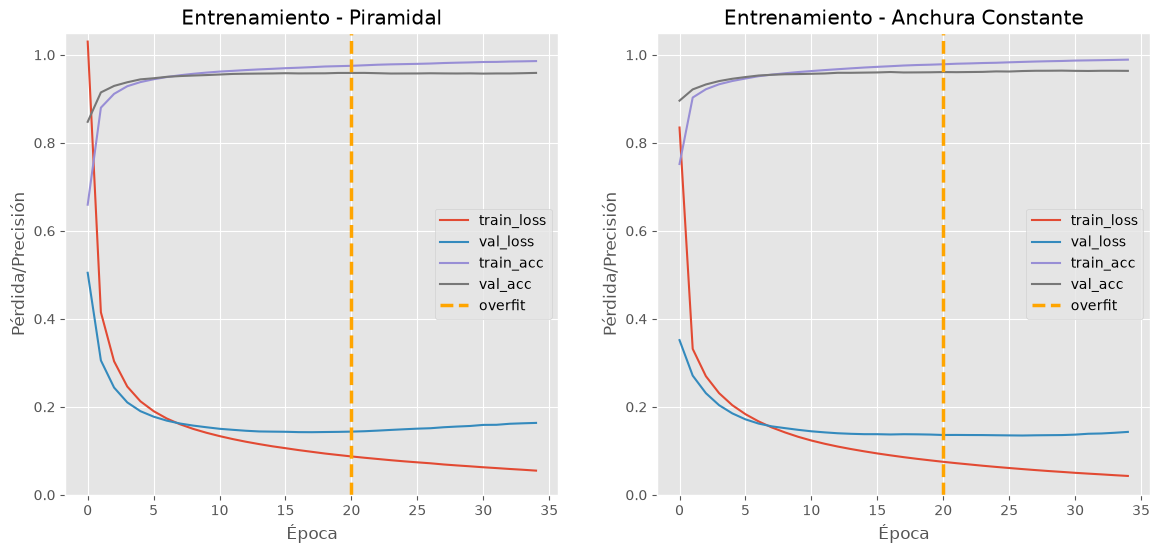

In [ ]:
#| echo: false
#| label: fig-training-history-design-a
#| fig-cap: "Evolución de la pérdida y la precisión de entrenamiento y validación para las arquitecturas del modelo A"
_, axes = utils.pp_history(H, overfit=[20, 20])
for ax in axes:
    ax.set_ylim(0, 1.05)
plt.show()

In [16]:
#| include: false
# Apoyo para analizar en detalle el comportamiento de la pérdida durante el entrenamiento
df = pd.DataFrame(H[0][1].history)
df['loss_aumenta'] = df['loss'].diff() > 0
df['val_loss_aumenta'] = df['val_loss'].diff() > 0
df

,accuracy,loss,val_accuracy,val_loss,loss_aumenta,val_loss_aumenta
0,0.659396,1.030157,0.847750,0.504647,False,False
1,0.879917,0.414916,0.914583,0.305494,False,False
2,0.911271,0.303590,0.929333,0.243791,False,False
3,0.928625,0.246108,0.937667,0.210096,False,False
4,0.938042,0.212519,0.944250,0.190103,False,False
5,0.944458,0.190153,0.946750,0.177632,False,False
6,0.949542,0.173420,0.950000,0.168593,False,False
7,0.953604,0.160354,0.951750,0.162076,False,False
8,0.956896,0.149847,0.952917,0.157351,False,False
9,0.959604,0.141105,0.954000,0.153597,False,False


La @tbl-eval-design-a presenta los resultados obtenidos al evaluar las dos arquitecturas en el conjunto de test. Los resultados muestran que los dos modelos mantienen una precisión muy similar cercana al 96%.

In [17]:
#| echo: false
#| output: asis
Evaluation_dict = {k: np.round(v, 4) for k, v in E}

print(utils.summary_evaluation(Evaluation_dict, "Comparación del rendimiento de las arquitecturas del modelo A", "#tbl-eval-design-a"))

|          |   Piramidal |   Anchura Constante |
|:---------|------------:|--------------------:|
| loss     |      0.1575 |              0.1418 |
| accuracy |      0.9591 |              0.9637 |
: Comparación del rendimiento de las arquitecturas del modelo A {#tbl-eval-design-a .striped .hover .sm}


## Modelo B (4 capas ocultas)

In [19]:
#| echo: false
input_shape = x_train_split.shape[1:]
hidden_layers_B = 4

units_piramid = (64, 32, 16, 8)
units_constant = 64

model_piramid = make_mlp(input_shape, hidden_layer=hidden_layers_B, units=units_piramid)
model_constant = make_mlp(
    input_shape, hidden_layer=hidden_layers_B, units=units_constant
)

models = [("Piramidal", model_piramid), ("Anchura Constante", model_constant)]

En la @tbl-4-hidden-layer-design se presentan las arquitecturas propuestas para entrenar el modelo B (4 capas ocultas).

- **Arquitectura piramidal (@tbl-4-hidden-layer-design-1):** formada por cuatro capas ocultas de 64, 32, 16 y 8 neuronas, respectivamente.
- **Arquitectura de anchura constante (@tbl-4-hidden-layer-design-2):** formada por cuatro capas ocultas de 64 neuronas cada una.

In [ ]:
#| echo: false
#| label: tbl-4-hidden-layer-design
#| tbl-cap: "Arquitecturas propuestas para el modelo B"
#| layout: [[48, -4, 48]]
for i, (name, model) in enumerate(models, start=1):
    display(
        Markdown(utils.summary_model(model, name, f"#tbl-4-hidden-layer-design-{i}", bformat="kb"))
    )

| Capa (tipo) | Salida | Parámetros |
|:------------|:-------|:-----------|
| flatten_2 (Flatten) | (None, 784) | 0 |
| dense_8 (Dense) | (None, 64) | 50,240 |
| dense_9 (Dense) | (None, 32) | 2,080 |
| dense_10 (Dense) | (None, 16) | 528 |
| dense_11 (Dense) | (None, 8) | 136 |
| dense_12 (Dense) | (None, 10) | 90 |
: Piramidal {#tbl-4-hidden-layer-design-1 .striped .hover .sm}

**Total de parámetros:** 53,074 (207.32 kb)

| Capa (tipo) | Salida | Parámetros |
|:------------|:-------|:-----------|
| flatten_3 (Flatten) | (None, 784) | 0 |
| dense_13 (Dense) | (None, 64) | 50,240 |
| dense_14 (Dense) | (None, 64) | 4,160 |
| dense_15 (Dense) | (None, 64) | 4,160 |
| dense_16 (Dense) | (None, 64) | 4,160 |
| dense_17 (Dense) | (None, 10) | 650 |
: Anchura Constante {#tbl-4-hidden-layer-design-2 .striped .hover .sm}

**Total de parámetros:** 63,370 (247.54 kb)

In [21]:
#| include: false
# Porcentaje de ahorro de parámetros de la arquitectura piramidal respecto a la constante
(models[0][1].count_params() - models[1][1].count_params()) / models[0][1].count_params()

-0.19399329238421825

In [22]:
#| include: false
# En este paso sólo se va a estudiar el efecto de las arquitecturas de los modelos MLP
# El resto de los parámetros se mantendrán constantes.
LEARNING_RATE = 0.05
BATCH_SIZE = 128
EPOCHS = 35

H = []

print("Entrenando el modelo B (4 capas ocultas)")
print("=" * 40)
for name, model in models:
    print(f"\nEntrenando arquitectura: {name}")
    print(f"Entrenando modelo: {name}")
    print("=" * 40)

    # Instancia para cada modelo
    optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE)
    loss = tf.keras.losses.SparseCategoricalCrossentropy()
    metrics = [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]

    model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

    history = model.fit(
        x_train_split,
        y_train_split,
        validation_data=(x_val_split, y_val_split),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
    )

    H.append((name, history))

Entrenando el modelo B (4 capas ocultas)

Entrenando arquitectura: Piramidal
Entrenando modelo: Piramidal
Epoch 1/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6384 - loss: 1.0881 - val_accuracy: 0.8398 - val_loss: 0.5299
Epoch 2/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8770 - loss: 0.4337 - val_accuracy: 0.9128 - val_loss: 0.3124
Epoch 3/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9218 - loss: 0.2880 - val_accuracy: 0.9336 - val_loss: 0.2309
Epoch 4/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9393 - loss: 0.2259 - val_accuracy: 0.9436 - val_loss: 0.1951
Epoch 5/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9494 - loss: 0.1890 - val_accuracy: 0.9470 - val_loss: 0.1778
Epoch 6/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9560 - loss: 0.1634 - val_accuracy: 0.9508 - val_loss: 0.1668
Epoch 7/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9616 - loss: 0.1442 - val_accuracy: 0.9530 - val_loss: 0.158

In [23]:
#| include: false
E = []
for name, model in models:
    print(f"\nEvaluando arquitectura: {name}")
    print("=" * 40)
    result = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)
    E.append((name, result))


Evaluando arquitectura: Piramidal
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9613 - loss: 0.1805

Evaluando arquitectura: Anchura Constante
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9703 - loss: 0.1335


### Comparación de resultados

En la @fig-training-history-design-b se observa la evolución de la pérdida y la precisión durante el entrenamiento de ambas arquitecturas.

Las curvas presentan un comportamiento muy parecido durante las primeras épocas, tanto la pérdida de entrenamiento como la de validación disminuyen rápidamente y la precisión aumenta a valores altos.

Sin embargo, aproximadamente a partir de la época 20 para ambas arquitecturas se aprecia overfitting, la pérdida en validación comienza a aumentar mientras que la de entrenamiento disminuye hasta aproximarse a cero.

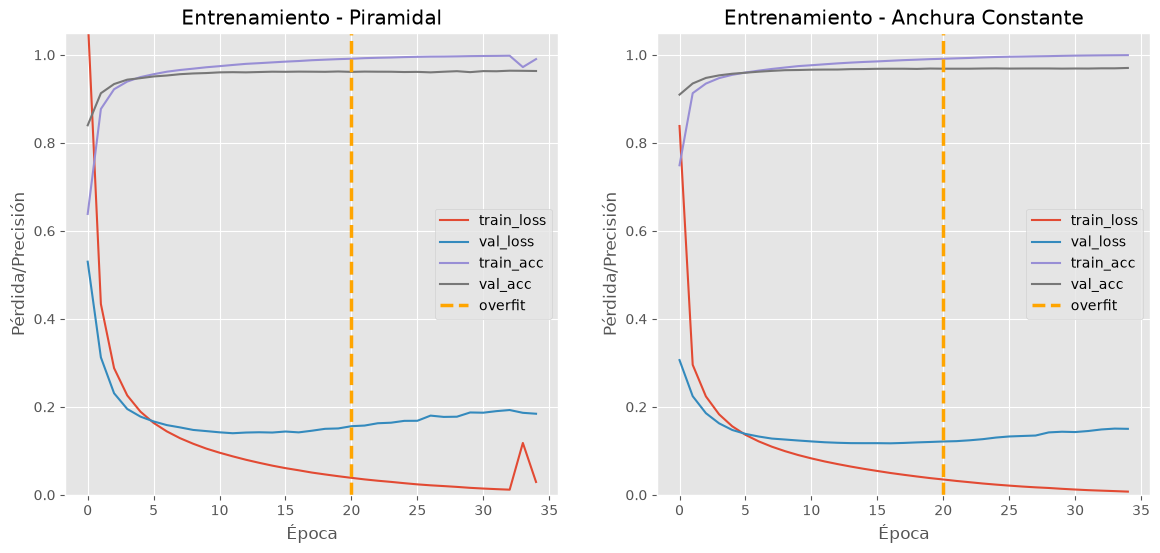

In [24]:
#| echo: false
#| label: fig-training-history-design-b
#| fig-cap: "Evolución de la pérdida y la precisión de entrenamiento y validación para las arquitecturas del modelo B"
_, axes = utils.pp_history(H, overfit=[20, 20])
for ax in axes:
    ax.set_ylim(0, 1.05)
plt.show()

In [25]:
#| include: false
# Apoyo para analizar en detalle el comportamiento de la pérdida durante el entrenamiento
df = pd.DataFrame(H[0][1].history)
df['loss_aumenta'] = df['loss'].diff() > 0
df['val_loss_aumenta'] = df['val_loss'].diff() > 0
df

,accuracy,loss,val_accuracy,val_loss,loss_aumenta,val_loss_aumenta
0,0.638375,1.088056,0.839833,0.529889,False,False
1,0.876958,0.433674,0.912750,0.312388,False,False
2,0.921792,0.287972,0.933583,0.230875,False,False
3,0.939271,0.225888,0.943583,0.195076,False,False
4,0.949396,0.189025,0.947000,0.177771,False,False
5,0.955958,0.163393,0.950833,0.166804,False,False
6,0.961625,0.144180,0.953000,0.158479,False,False
7,0.965500,0.128739,0.956000,0.153253,False,False
8,0.968562,0.116087,0.957667,0.147487,False,False
9,0.971750,0.105024,0.958583,0.144823,False,False


La @tbl-eval-design-b presenta los resultados obtenidos al evaluar las dos arquitecturas en el conjunto de test. Los resultados muestran que los dos modelos mantienen una elevada capacidad de generalización.

In [26]:
#| echo: false
#| output: asis
Evaluation_dict = {k: np.round(v, 4) for k, v in E}

print(utils.summary_evaluation(Evaluation_dict, "Comparación del rendimiento de las arquitecturas del modelo B", "#tbl-eval-design-b"))

|          |   Piramidal |   Anchura Constante |
|:---------|------------:|--------------------:|
| loss     |      0.1805 |              0.1335 |
| accuracy |      0.9613 |              0.9703 |
: Comparación del rendimiento de las arquitecturas del modelo B {#tbl-eval-design-b .striped .hover .sm}


## Conclusión

Las cuatro arquitecturas planteadas presentan un rendimiento similar, en la tarea de clasificar los dígitos manuscritos del conjunto MNIST, alcanzando precisiones comprendidas entre el 95,91% y el 97,03%.

En el modelo A, la arquitectura de anchura constante obtiene un precisión ligeramente superior a la piramidal (96,37% frente a 95,91%), aunque utiliza un 6,5% más de parámetros.

En el modelo B, la arquitectura de anchura constante también ofrece mejores resultados (97,03% frente 96,13%), utilizando aproximadamente un 19,4% más de parámetros que la arquitectura piramidal.

En consecuencia, para el siguiente desafío se seleccionan las arquitecturas de anchura constante para los dos modelos, con el objetivo de estudiar como influyen las técnicas de optimización y regularización sobre una red con más capacidad de representación.

::: {.callout-note}
Una red más densa, con mayor número de parámetros, dispone de más capacidad de representación, pero tiene un mayor riesgo de overfitting, requiere más espacio en disco para almacenarla y más recursos computacionales para entrenarla.

Para reducir este riesgo, se utilizan técnicas de regularización y estrategias como el early stopping, que permiten detener el entrenamiento cuando el rendimiento sobre los datos de validación deja de mejorar.
:::

# Ajuste de la tasa de aprendizaje

Para encontrar la tasa de aprendizaje adecuada, se implementa el callback `LearningRateFinder`, basado en la implementación que realiza la biblioteca fast.ai [@fastai] del procedimiento Learning Rate Range Test, propuesto en Cyclical Learning Rates for Training Neural Networks [@smith2017].

El procedimiento consiste en ir aumentando la tasa de aprendizaje de forma exponencial en intervalo predefinido, registrando la pérdida durante el entrenamiento. Finalmente, se visualiza la evolución de la pérdida en función de la tasa de aprendizaje lo que permite identificar las regiones donde esta disminuye más rápidamente.

A partir de esta curva, se puede estimar una tasa de aprendizaje inicial utilizando diferentes criterios, como el punto de mayor pendiente negativa (Minimum Gradient), o la identificación de la región de descenso más prolongado (Valley) [@fastai; @chang2019].

In [27]:
# | include: false
class LearningRateFinder(Callback):
    """
    Track de la pérdida durante el entrenamiento en función del learning rate.
    Permite encontrar un learning rate adecuado para el entrenamiento.

    Implemetación basada en:
    - Librería fast.ai: https://github.com/fastai/fastai/blob/master/fastai/callbacks/learner.py#L123
    - Paper Original: https://arxiv.org/abs/1506.01186
    """

    def __init__(self, start_lr=1e-7, steps_per_epoch=None, epochs=None, stop_factor=4):
        super().__init__()

        # Learning rate para iniciar la búsqueda
        self.start_lr = start_lr

        # Track de los parámetro originales del modelo
        self._save_weights = None
        self._save_lr = None

        # Control de la pérdida suavizada, del mejor valor y factor de parada
        self.avg_loss = 0
        self.beta = 0.98
        self.stop_factor = stop_factor
        self.best_loss = float("inf")

        # Número de batch actual y total de batches de la búsqueda
        self.batch_num = 0
        self.num_batches = epochs * steps_per_epoch
        # Factor exponencial para incrementar el leaning rate en cada iteración
        self.lr_mult = None

        # Track de la evolución de la pérdida y el learning rate
        self.losses = []
        self.lrs = []

        # Learning rate sugerido basado en la curva de pérdida
        self.min_loss = None
        self.min_gradient = None
        self.lr_valley = None

    def on_train_begin(self, logs=None):
        """Inicializa el learning rate y guarda los parámetros originales del modelo."""
        # Guarda los parámetros originales del modelo y el learning rate inicial
        self._save_lr = self.model.optimizer.learning_rate.numpy()
        self.model.optimizer.learning_rate = self.start_lr

        self._save_weights = self.model.get_weights()

        end_lr = 10 if self.start_lr < 10 else self.start_lr * 10
        # El factor de exponencial para incrementar el learning rate en cada iteración
        self.lr_mult = (end_lr / self.start_lr) ** (1 / self.num_batches)

    def on_train_end(self, logs=None):
        """Restaura los parámetros originales del modelo y el learning rate al finalizar la búsqueda."""
        self.model.set_weights(self._save_weights)
        self.model.optimizer.learning_rate = self._save_lr

        self.compute_suggested_lr()

    def on_train_batch_end(self, batch, logs=None):
        """
        Almacena la pérdida y el learning rate del batch actual y actualiza el learning rate para el siguiente batch.
        """
        self.batch_num += 1

        # Track de learning rate y la perdida suavizada
        lr = self.model.optimizer.learning_rate.numpy()
        self.lrs.append(lr)

        loss = logs.get("loss")
        self.avg_loss = self.beta * self.avg_loss + (1 - self.beta) * loss
        smoothed_loss = self.avg_loss / (1 - self.beta**self.batch_num)
        self.losses.append(smoothed_loss)

        # Check para detener el entreno si la pérdida supera el mejor valor multiplicado por el factor de parada
        if smoothed_loss > self.best_loss * self.stop_factor:
            self.model.stop_training = True
            print("\nLa pérdida ha superado el mejor valor multiplicado por el factor de parada, se detiene la búsqueda de learning rate")
            return

        if smoothed_loss < self.best_loss:
            self.best_loss = smoothed_loss

        # Si el modelo casca durante el entreno y empieza a producir NaNs, se detiene el entrenamiento
        if np.isnan(smoothed_loss):
            self.model.stop_training = True
            print("\nEl entrenamiento entra en inestabilidad (NaN en la pérdida), se detiene la búsqueda de learning rate")
            return

        # Actualiza el learning rate para el siguiente batch
        lr *= self.lr_mult
        self.model.optimizer.learning_rate = lr

    def compute_suggested_lr(self):
        """
        Calcula los learning rates sugeridos basados en la curva de pérdida.

        - min_gradient: El índice del gradiente mínimo en una sección de la curva de pérdida.
        - min_loss: El índice de la pérdida mínima en la curva de pérdida.
        """
        self.lr_valley = self.valley(self.lrs, self.losses)
        self.min_loss = np.argmin(self.losses)
        try:
            self.min_gradient = (
                np.gradient(np.array(self.losses[30 : self.min_loss]))
            ).argmin()
        except Exception:
            self.min_gradient = None

    def valley(self, lrs, losses):
        """
        Busca la regisón decreciente más larga en la secuencia de pérdidas.
        Ver:
        - https://forums.fast.ai/t/automated-learning-rate-suggester/44199/30
        """
        n = len(losses)
        max_start = 0
        max_end = 0

        lds = [1] * n
        for i in range(1, n):
            for j in range(i):
                if (losses[i] < losses[j]) and (lds[i] < lds[j] + 1):
                    lds[i] = lds[j] + 1
                if lds[i] > lds[max_end]:
                    max_end = i
                    max_start = max_end - lds[max_end]

        sections = (max_end - max_start) / 3
        return max_start + int(sections) + int(sections / 2)

    def plot_loss(self, ax=None, n_skips_begin=10, n_skips_end=5, suggest=False):
        """
        Imprime la curva de pérdida en función del learning rate.

        Parámetros:
        ===========
        - n_skips_begin: Número de batches iniciales a omitir en la gráfica.
        - n_skips_end: Número de batches finales a omitir en la gráfica.
        - suggest: Si es True, marca en la gráfica los learning rates sugeridos.

        Retorna:
        ===========
        - ax: El objeto de ejes de matplotlib.
        """
        if ax is None:
            fig, ax = plt.subplots()

        slice_range = slice(n_skips_begin, -n_skips_end)

        ax.plot(self.lrs[slice_range], self.losses[slice_range])
        ax.set_xlabel("Tasa de aprendizaje (log scale)")
        ax.set_ylabel("Pérdida")
        ax.set_xscale("log")

        if suggest:
            valley = self.valley(self.lrs, self.losses)

            ax.plot(
                self.lrs[valley],
                self.losses[valley],
                markersize=10,
                marker="o",
                color="red",
                label=f"Valle más largo: {self.lrs[valley]:.2E}",
            )
            if self.min_gradient is not None:
                ax.plot(
                    self.lrs[self.min_gradient],
                    self.losses[self.min_gradient],
                    markersize=10,
                    marker="o",
                    color="purple",
                    label=f"Mínimo gradiente: {self.lrs[self.min_gradient]:.2E}",
                )
            ax.plot(
                self.lrs[self.min_loss],
                self.losses[self.min_loss],
                markersize=10,
                marker="o",
                color="green",
                label=f"Pérdida mínima: {self.lrs[self.min_loss]:.2E}",
            )
            ax.legend(loc="upper right")

        return ax

    def suggested_lr(self):
        """
        Retorna la tasa de aprendizaje sugeridas basada en el valle más largo.

        Retorna:
        ===========
        - lr_min_gradient: El learning rate correspondiente al gradiente mínimo en una sección de la curva de pérdida.
        - lr_min_loss: El learning rate correspondiente a la pérdida mínima, dividido por 10.
        - lr_valley: El learning rate correspondiente al valle más largo en la curva de pérdida, sitúa el punto en la sección media del valle.
        """
        lr_min_loss = self.lrs[self.min_loss] / 10
        if self.min_gradient is not None:
            lr_min_gradient = self.lrs[self.min_gradient]
        else:
            lr_min_gradient = None
        lr_valley = self.lrs[self.valley(self.lrs, self.losses)]

        return lr_min_gradient, lr_min_loss, lr_valley

In [28]:
#| include: false
# Diseñar el modelo
input_shape = x_train_split.shape[1:]
hidden_layers_A = 3
hidden_layers_B = 4
units_A = 32
units_B = 64

# Parámetros de entrenamiento
# Aumenta el tamaño del batch para acelerar el entrenamiento
MIN_LEARNING_RATE = 1e-5
BATCH_SIZE = 128
EPOCHS = 35

# Almacena los resultados de la búsqueda de tasa de aprendizaje
lr_find_results = {}

for name, hidden_layers, units in [
    ("Modelo A", hidden_layers_A, units_A),
    ("Modelo B", hidden_layers_B, units_B),
]:
    print(
        f"\nBúsqueda de tasa de aprendizaje para {name} (con {hidden_layers} capas ocultas)"
    )
    print("=" * 40)

    # Crear el modelo
    model = make_mlp(input_shape, hidden_layer=hidden_layers, units=units)

    # Instancia única para cada modelo
    optimizer = tf.keras.optimizers.SGD(learning_rate=MIN_LEARNING_RATE)
    loss = tf.keras.losses.SparseCategoricalCrossentropy()
    metrics = [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]

    lr_finder = LearningRateFinder(
        steps_per_epoch=len(x_train_split) // BATCH_SIZE, epochs=EPOCHS
    )

    model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

    history = model.fit(
        x_train_split,
        y_train_split,
        validation_data=(x_val_split, y_val_split),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=[lr_finder],
    )
    lr_find_results[name] = lr_finder


Búsqueda de tasa de aprendizaje para Modelo A (con 3 capas ocultas)
Epoch 1/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3393 - val_accuracy: 0.0983 - val_loss: 2.3394
Epoch 2/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3393 - val_accuracy: 0.0983 - val_loss: 2.3393
Epoch 3/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3393 - val_accuracy: 0.0983 - val_loss: 2.3393
Epoch 4/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3392 - val_accuracy: 0.0983 - val_loss: 2.3392
Epoch 5/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3391 - val_accuracy: 0.0983 - val_loss: 2.3391
Epoch 6/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3389 - val_accuracy: 0.0982 - val_loss: 2.3388
Epoch 7/35
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0965 - loss: 2.3386 - val_accuracy: 0.0982 - val_loss: 2.3384
Epoch 8/35
375/375 ━━━━━━━━━━━━━━━━

Tras realizar la búsqueda de la tasa de aprendizaje para los modelos A y B, podemos observar las curvas de pérdida y las tasas de aprendizaje sugeridas en la @fig-learning-rate-finder.


En la @fig-learning-rate-finder, se visualiza la evolución de la pérdida en función de la tasa de aprendizaje para los modelos A y B. Sobre la curva se marcan las tasas de aprendizaje sugeridas según la literatura [@chang2019].

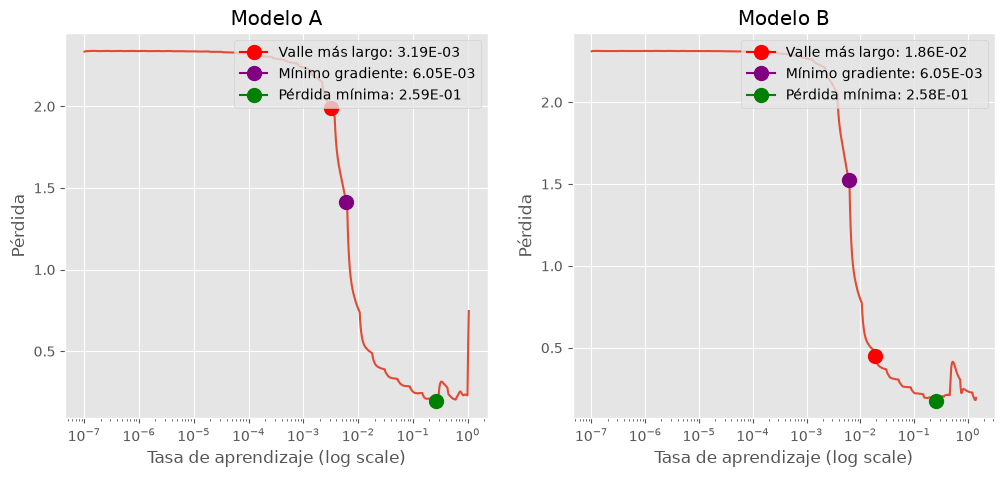

In [ ]:
#| echo: false
#| label: fig-learning-rate-finder
#| fig-cap: "Curvas de pérdida en función de la tasa de aprendizaje para los modelos A y B"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))


lr_find_results["Modelo A"].plot_loss(ax=ax1, suggest=True)
ax1.set_title("Modelo A")
lr_find_results["Modelo B"].plot_loss(ax=ax2, suggest=True)
ax2.set_title("Modelo B")

plt.show()

In [30]:
#| include: false
lr_suggestions = {}
for name, finder in lr_find_results.items():
    min_gradient_loss, min_loss, valley_loss = finder.suggested_lr()
    lr_suggestions[name] = list(zip(("min_gradient", "min_loss", "valley"), (min_gradient_loss, min_loss, valley_loss)))
    # lr_suggestions[name] = list(zip(("valley",), (valley_loss,)))

In [31]:
#| include: false
# Diseñar el modelo
input_shape = x_train_split.shape[1:]
hidden_layers_A = 3
hidden_layers_B = 4
units_A = 32
units_B = 64

# Parámetros de entrenamiento
BATCH_SIZE = 128
EPOCHS = 1_000


# Almacena los resultados finales
results = {}

for name, hidden_layers, units in [
    ("Modelo A", hidden_layers_A, units_A),
    ("Modelo B", hidden_layers_B, units_B),
]:
    print(
        f"\nTest de la mejor tasa de aprendizaje para el modelo {name} (con {hidden_layers} capas ocultas)"
    )
    print("=" * 40)
    for criterio, lr_suggested in lr_suggestions[name]:
        print(
            f"\nEntrenando con criterio: {criterio}, tasa de aprendizaje sugerida: {lr_suggested}"
        )
        print("=" * 40)

        # Crear el modelo
        model = make_mlp(input_shape, hidden_layer=hidden_layers, units=units)

        # Instancia única para cada modelo
        optimizer = tf.keras.optimizers.SGD(learning_rate=float(lr_suggested))
        loss = tf.keras.losses.SparseCategoricalCrossentropy()
        metrics = [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]

        # Callbacks
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
        )

        pretty_name = re.sub(r"\s+", "_", name)
        checkpoint_filepath = Path("results") / pretty_name / f"{criterio}.keras"
        checkpoint_filepath.parent.mkdir(parents=True, exist_ok=True)
        checkpoint = tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_filepath),
            save_best_only=True,
            monitor="val_loss",
        )

        model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

        history = model.fit(
            x_train_split,
            y_train_split,
            validation_data=(x_val_split, y_val_split),
            batch_size=BATCH_SIZE,
            epochs=EPOCHS,
            callbacks=[early_stopping, checkpoint],
        )
        results.setdefault(name, {})[criterio] = {
            "lr_suggested": lr_suggested,
            "history": history.history.copy(),
            "checkpoint": str(checkpoint_filepath),
        }


Test de la mejor tasa de aprendizaje para el modelo Modelo A (con 3 capas ocultas)

Entrenando con criterio: min_gradient, tasa de aprendizaje sugerida: 0.0060521699488162994
Epoch 1/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2101 - loss: 2.1987 - val_accuracy: 0.3273 - val_loss: 1.9898
Epoch 2/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4615 - loss: 1.6546 - val_accuracy: 0.5890 - val_loss: 1.2667
Epoch 3/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6950 - loss: 1.0260 - val_accuracy: 0.7818 - val_loss: 0.7869
Epoch 4/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7975 - loss: 0.7123 - val_accuracy: 0.8322 - val_loss: 0.5969
Epoch 5/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8344 - loss: 0.5768 - val_accuracy: 0.8550 - val_loss: 0.5029
Epoch 6/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8566 - loss: 0.4993 - val_accuracy: 0.8733 - val_loss: 0.4446
Epoch 7/1000
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s

## Conclusiones

Los resultados de validación de la @tbl-final-validation-results muestran que los tres criterios de selección de tasa de aprendizaje obtienen precisiones similares.

Para el modelo A, el criterio valley obtiene la mayor precisión, mientras que en el modelo B el mejor resultado corresponde a min_gradient. Estas diferencias son muy reducidas, lo que no nos permite establecer la superioridad de un criterio sobre los demás.

In [190]:
#| echo: false
#| label: tbl-final-validation-results
#| tbl-cap: "Precisión de la validación según el criterio de la tasa de aprendizaje"
final_data = {
    "Modelo A": (
        results["Modelo A"]["min_gradient"]["history"]["val_accuracy"][-1],
        results["Modelo A"]["min_loss"]["history"]["val_accuracy"][-1],
        results["Modelo A"]["valley"]["history"]["val_accuracy"][-1]
    ),
    "Modelo B": (
        results["Modelo B"]["min_gradient"]["history"]["val_accuracy"][-1],
        results["Modelo B"]["min_loss"]["history"]["val_accuracy"][-1],
        results["Modelo B"]["valley"]["history"]["val_accuracy"][-1]
    )
}
df = pd.DataFrame(final_data, index=["min_gradient", "min_loss", "valley"])
df = (df * 100).round(2)

display(Markdown("\n".join([
    df.to_markdown(),
    ": {.striped .hover .sm}"
])))

|              |   Modelo A |   Modelo B |
|:-------------|-----------:|-----------:|
| min_gradient |      96.17 |      96.78 |
| min_loss     |      96.13 |      96.57 |
| valley       |      96.8  |      96.68 |
: {.striped .hover .sm}

In [34]:
#| include: false
model_a = tf.keras.models.load_model(results["Modelo A"]["valley"]["checkpoint"])
model_b = tf.keras.models.load_model(results["Modelo B"]["min_gradient"]["checkpoint"])

Evaluation_dict = {
    "Modelo A": [round(x, 4) for x in  model_a.evaluate(x_test, y_test)],
    "Modelo B": [round(x, 4) for x in model_b.evaluate(x_test, y_test)]
}

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - accuracy: 0.9674 - loss: 0.1142
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 686us/step - accuracy: 0.9692 - loss: 0.1024


Finalmente, la evaluación sobre el conjunto de prueba, presentada en la @tbl-final-evaluation-results, muestran un precisión del 96,74% para el modeloA y del 96,92% para el modelo B.

Ambas arquitecturas presentan un rendimiento muy similar sobre datos no utilizados durante el entrenamiento, demostrando una buena capacidad de generalización.

::: {.callout-note}
En el modelo B, el resultado obtenido tras el ajuste de la tasa de aprendizaje no produce una mejora respecto al entrenamiento inicial donde se seleccionó unas tasa de aprendizaje estimada. La precisión pasa del 97,03% al 96,92%.

El resultado demuestra que los criterios para la selección utilizados por el `Learning Rate Finder` permiten encontrar tasas de aprendizaje candidatas, pero no garantizan una mejora en el rendimiento final del modelo. Por tanto, la principal ventaja de este método radica en que nos proporciona un método heurístico para realizar esta selección.
:::

In [184]:
#| echo: false
#| output: asis
print(utils.summary_evaluation(Evaluation_dict, "Pérdida y precisión de los modelos en el conjunto de prueba", "#tbl-final-evaluation-results"))

|          |   Modelo A |   Modelo B |
|:---------|-----------:|-----------:|
| loss     |     0.1142 |     0.1024 |
| accuracy |    96.74   |    96.92   |
: Pérdida y precisión de los modelos en el conjunto de prueba {#tbl-final-evaluation-results .striped .hover .sm}


# Resultados

En este último punto se presentan los resultados finales. Se trabajará con el modelo A para facilitar la visualización de las representaciones aprendidas en las capas ocultas.

In [94]:
#| include: false
y_preds_prob = model_a.predict(x_test)
y_preds_val = np.argmax(y_preds_prob, axis=1)


def make_individual_prediction(idx, model=model_a, x_data=x_test):
    """
    Predice la probabilidad de cada clase para un ejemplo específico del conjunto de datos.

    Parámetros:
    ===========
    - idx: Índice del ejemplo en el conjunto de datos.
    - model: Modelo de Keras a utilizar para la predicción (por defecto model_a).
    - x_data: Conjunto de datos de entrada (por defecto x_test).

    Retorna:
    ===========
    - tuple: Una tupla de pares (clase, probabilidad) ordenada de mayor a menor probabilidad.
    """
    preds = model.predict(tf.stack([x_data[idx]]), verbose=0)[0]
    probs = tuple(zip(range(len(preds)), preds))
    order_dict = tuple(sorted(probs, key=lambda item: item[1], reverse=True))
    return order_dict

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 528us/step


En la @fig-mlp-correct-predictions se muestran ejemplos de algunas predicciones correctas realizadas por el modelo. En la mayoría de los casos seleccionados, la probabilidad asignada a la clase predicha es elevada.

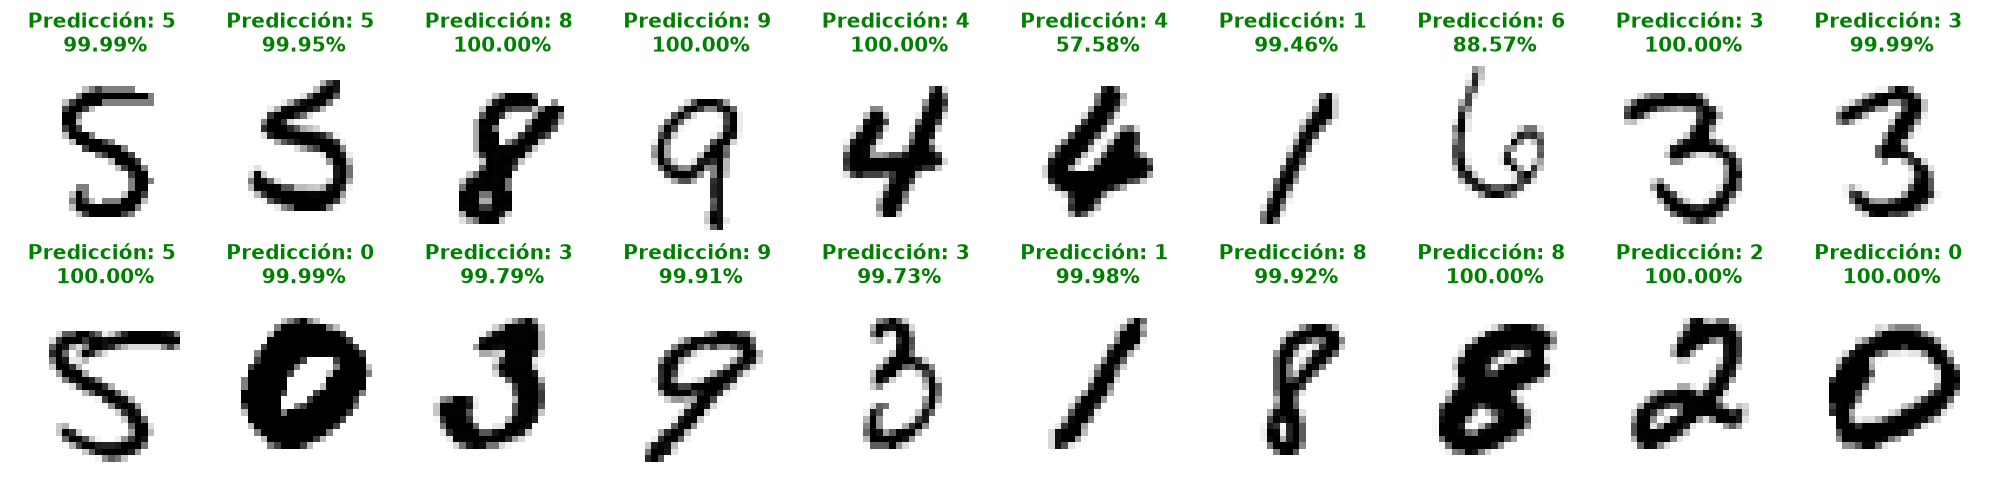

In [ ]:
#| echo: false
#| label: fig-mlp-correct-predictions
#| fig-cap: "Predicciones correctas del modeloma"
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
axes = axes.ravel()
# Predicciones correrctas
true_mask = y_preds_val == y_test
# Selección aleatoria de 20 predicciones correctas
indices_true = np.random.permutation(np.where(true_mask)[0])[:20]

fig

for ax, idx in zip(axes, indices_true):
    img = x_test[idx]
    label = y_test[idx]
    clase, prob = make_individual_prediction(idx)[0]

    title = f"Predicción: {clase}\n {prob*100:.2f}%"
    utils.plot_image(img, ax=ax, title=title, cmap="binary")
    ax.title.set_color("green")
    ax.title.set_fontweight("bold")

plt.tight_layout()
plt.show()

Mientras, en la @fig-mlp-incorrect-predictions se presentan ejemplos de predicciones incorrectas. Algunas de la imágenes presentadas contienen trazos ambiguos que hacen difícil su interpretación incluso para una persona. Algunas de las predicciones muestran que la probabilidad entre la clase errónea predicha y la real está bastante ajustada, sin embargo, otras predicciones muestran una confianza muy elevada en el error. 

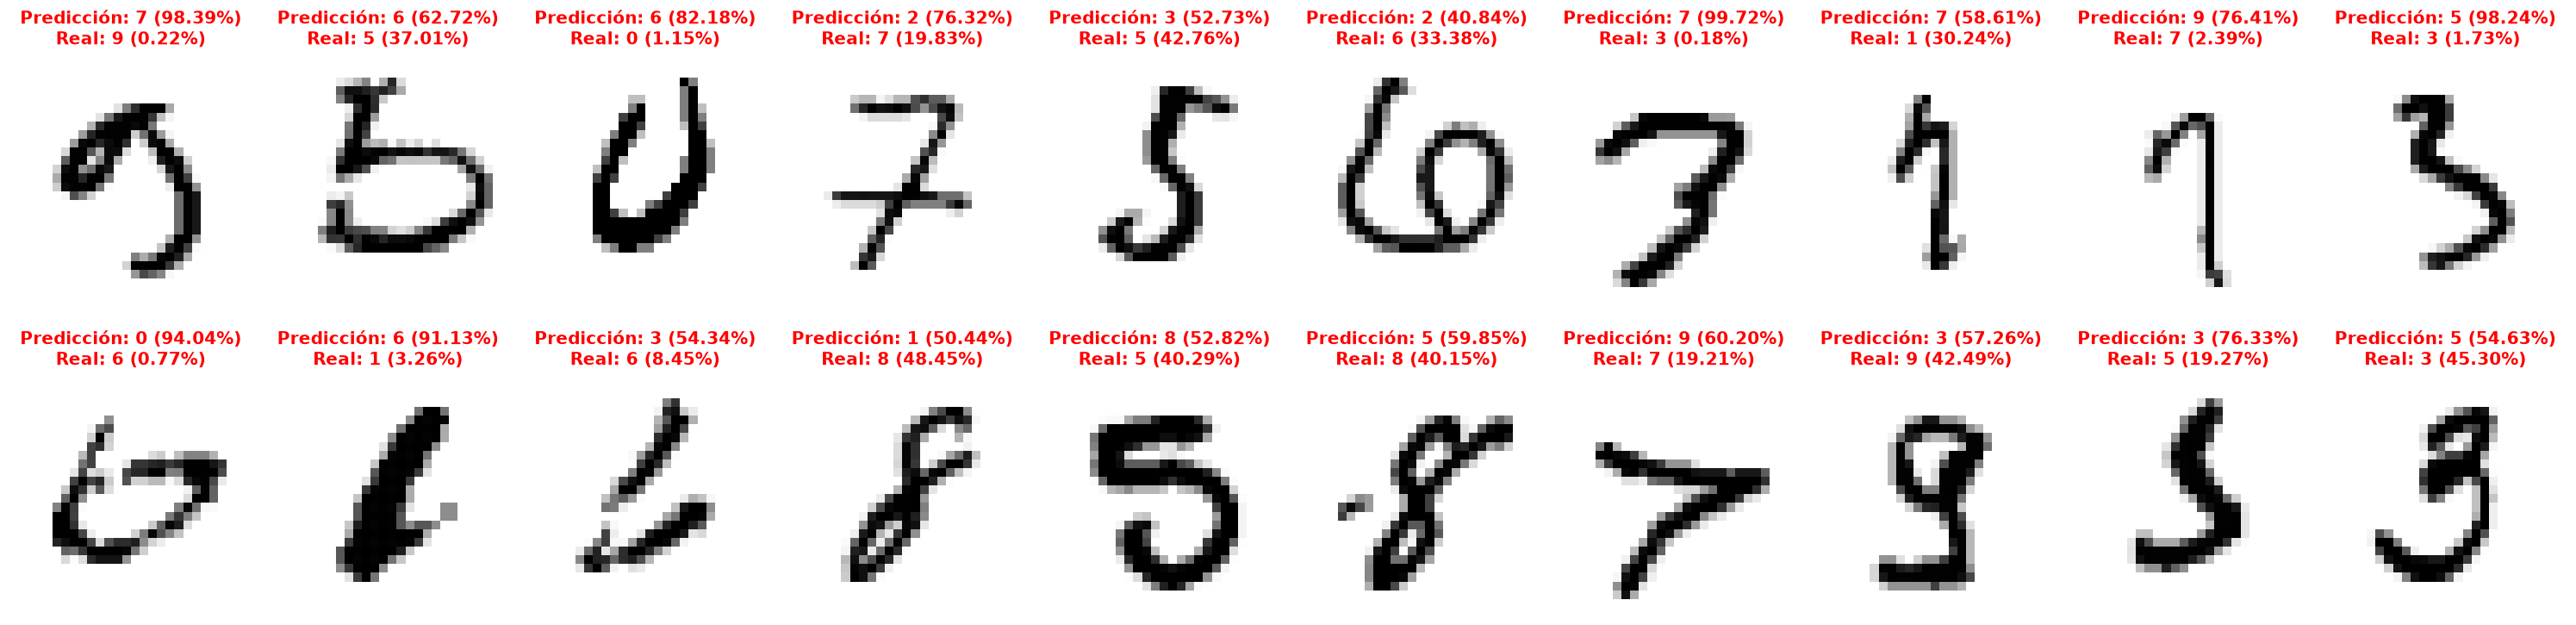

In [ ]:
#| echo: false
#| label: fig-mlp-incorrect-predictions
#| fig-cap: "Predicciones incorrectas del modelo"
fig, axes = plt.subplots(2, 10, figsize=(30, 8))
axes = axes.ravel()
# Predicciones incorrectas
false_mask = y_preds_val != y_test
# Selección aleatoria de 20 predicciones incorrectas
indices_false = np.random.permutation(np.where(false_mask)[0])[:20]

for ax, idx in zip(axes, indices_false):
    img = x_test[idx]
    label = y_test[idx].item()
    pred = make_individual_prediction(idx)

    # Número predicho y probabilidad
    clase, prob = pred[0]
    # Etiqueta real y probabilidad
    real_prob = dict(pred)[label]

    title = f"Predicción: {clase} ({prob*100:.2f}%)\nReal: {label} ({real_prob*100:.2f}%)"
    utils.plot_image(img, ax=ax, title=title, cmap="binary")
    ax.title.set_color("red")
    ax.title.set_fontweight("bold")

plt.tight_layout()
plt.show()

Inicialmente se planteo que los dígitos 1, 7 y 9 podrían presentar dificultades de clasificación debido a la similitud de sus trazos.

Finalmente en la @tbl-mlp-incorrect-predictions, se observa que los dígitos 8 y 9 acumulan el mayor porcentaje de clasificaciones erróneas, seguidas de los dígitos 5, 7. Sin embargo, el 1 es el que menos errores presenta.

La matriz de confusión de la @fig-confusion-matrix-predictions, permite detectar las clases entre las que se producen más errores. Destaca principalmente la confusión entre los dígitos 4 y 9 con 20 imágenes del número 9 clasificadas como 4. 

In [175]:
#| echo: false
#| label: tbl-mlp-incorrect-predictions
#| tbl-cap: "Predicciones incorrectas por clase"
df = pd.concat([
    pd.DataFrame(y_test[false_mask]).value_counts(),
    pd.DataFrame(y_test).value_counts()
], axis=1).reset_index()
df.columns = ["Clase", "Incorrectas", "Totales"]
df['Porcentaje Incorrectas'] = (df['Incorrectas'] / df['Totales'] * 100).round(2)

display(Markdown("\n".join([
    df.to_markdown(index=False),
    ": {.striped .hover .sm}"
])))

|   Clase |   Incorrectas |   Totales |   Porcentaje Incorrectas |
|--------:|--------------:|----------:|-------------------------:|
|       8 |            45 |       974 |                     4.62 |
|       9 |            45 |      1009 |                     4.46 |
|       5 |            39 |       892 |                     4.37 |
|       7 |            39 |      1028 |                     3.79 |
|       3 |            37 |      1010 |                     3.66 |
|       4 |            32 |       982 |                     3.26 |
|       6 |            31 |       958 |                     3.24 |
|       2 |            29 |      1032 |                     2.81 |
|       0 |            18 |       980 |                     1.84 |
|       1 |            11 |      1135 |                     0.97 |
: {.striped .hover .sm}

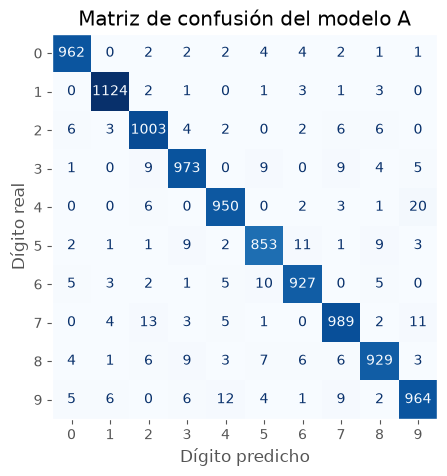

In [214]:
#| echo: false
#| label: fig-confusion-matrix-predictions
#| fig-cap: "Matriz de confusión de las predicciones del modelo"
fig, ax = plt.subplots(figsize=(5, 5))

cm = confusion_matrix(y_test, y_preds_val, labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))

disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matriz de confusión del modelo A")
ax.set_xlabel("Dígito predicho")
ax.set_ylabel("Dígito real")
ax.grid(False)

En @fig-hidden-layer-representation se representan los pesos aprendidos por las 32 neuronas de la primera capa oculta, reorganizados como una matriz de 28x28 píxeles para facilitar su interpretación visual.

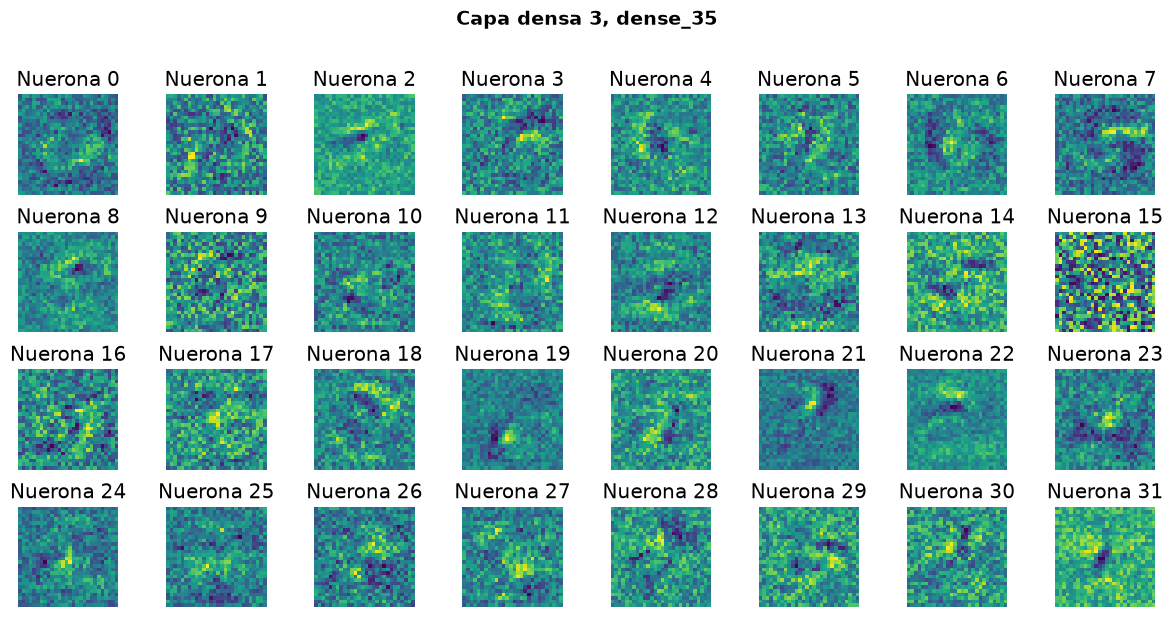

In [ ]:
#| echo: false
#| label: fig-hidden-layer-representation
#| fig-cap: "Representación visual de los pesos de la primera capa densa"
# Visualización de los pesos de la primera capa densa del modelo
layer_1 = model_a.layers[1]
weights = layer_1.get_weights()[0]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
axes = axes.ravel()

fig.suptitle(f"Capa oculta 1", fontweight='bold', fontsize=14, y=1.02)
for i, ax in enumerate(axes):
    img = weights[:, i].reshape(28, 28)
    utils.plot_image(img, ax=ax,title=f"Nuerona {i}", cmap='viridis')

fig.tight_layout()
plt.show()

```{=latex}
\clearpage
```

# Referencias {.unnumbered}

::: {#refs}
:::
